# Workshop 2 — Validated London Fire Brigade analysis
**Business Intelligence · Group 11 · Matías Muñoz Hoffmann and Clemente Ibarra**

## tl;dr
We continue the C1 question: which boroughs and dispatch hours warrant closer investigation of longer published vehicle mobilisation-to-arrival times? Following the team's report of the instructor's C1 feedback, the **primary KPI is now the share of eligible mobilisations lasting more than 10 minutes**; P90 remains a supporting distribution measure. In the retained 2023–2024 source snapshot, 26,172 of 384,627 eligible mobilisations (6.81%) exceed 10 minutes. This threshold is an **exploratory team choice, not an LFB service standard**. W2 adds reproducible data checks, a 25% sample, a contextual leakage audit, and chronological train/validation/test subsets. The test subset is a retrospective robustness check, not a credible estimate of unseen predictive performance: W1/C1 already inspected the full source.

## Context & Methods
**Proposed decision owner:** an LFB operations-planning analyst. **Proposed decision:** select places and periods for contextual review; do not change staffing or dispatch rules from these summaries alone. **Observation unit:** one published vehicle mobilisation, not one incident. **Decision/prediction time for the leakage audit:** immediately when a vehicle is mobilised. No model is fitted in W2.

**Objective:** identify segments with a higher frequency of longer observed mobilisation-to-arrival times. **Primary KPI:** `100 × count(AttendanceTimeSeconds > 600) / count(eligible mobilisations)` within the stated period/segment. The numerator and denominator use the same C1 eligibility rules. Higher values identify questions for review, not poor performance or a causal effect. Ten minutes is fixed before the W2 sample and split; it was selected after C1's whole-data EDA and is not an independently validated operational threshold. Report eligible `n`, median and P90 beside the KPI.

**Source:** [official LFB mobilisation catalogue](https://data.london.gov.uk/dataset/london-fire-brigade-mobilisation-records-24r65); local source snapshot retrieved 23 September 2026, as recorded in `GROUP_11_C1/data/source_manifest.json`. C1's executed `GROUP_11_C1/analysis/C1_LFB.ipynb`, audit and cleaned case are retained. [LFB's published attendance methodology](https://www.london-fire.gov.uk/media/8863/foia84201-response-times-of-fire-brigades-and-data-collation-response.pdf) uses further first/second-appliance and exclusion rules; our KPI is not that official measure.

### Feedback to action
| Source | Issue | Correction and changed conclusion | Notebook evidence |
|---|---|---|---|
| C1 instructor comment, as reported by the team on 22 October 2026 | The presented P90 was challenged as the primary KPI. | Replace it with the explicit proportion above 10 minutes. Keep P90 as context; do not call the new threshold official. The C1 claim that Hillingdon has a high P90 becomes a question about its higher observed **share** over 10 minutes. | KPI calculation, borough comparison, management summary |
| Self-audit of C1 coverage | 31 December 2024 has no records. | Do not insert a zero. Mark December 2024 partial and exclude it from complete-month trend comparisons; retain all published rows in the period-wide KPI. | Coverage checks, monthly figure |
| Self-audit of C1 geography | Missing borough labels remain in eligible records. | Keep `Unknown` in the global denominator, show it separately, and omit it from named-borough ranking. No imputation. | Validation checks, borough figure |
| Self-audit of W1/C1 exploration | The whole source informed earlier choices. | Treat the chronological test subset as an independent calculation after the W2 protocol is fixed, **not** as a pristine unseen prediction benchmark. | Sampling, leakage audit, holdout section |

**Change to the C1 conclusion:** P90 differences still describe the tail, but the primary W2 comparison is the fraction of published eligible mobilisations above 10 minutes. Geographic/hourly contrasts remain unadjusted. No conclusion about causes, crew quality or resource changes follows.

### Important variables and plausible constraints
| Variable | Expected type and meaning | Plausible values / missing meaning |
|---|---|---|
| `ResourceMobilisationId` | Identifier of one vehicle mobilisation | Nonmissing and unique in the cleaned case; duplicates/conflicts are audited in C1. |
| `IncidentNumber` | Incident identifier; multiple vehicles may share it | Nonmissing; repetition is expected and matters for splitting. |
| `DateAndTimeMobilised` | Dispatch timestamp, GMT in the source dictionary | Parseable and in the selected period; missing would prevent temporal use. |
| `DateAndTimeArrived` | Arrival timestamp | Must not precede mobilisation; unavailable at dispatch, so prohibited as a feature. |
| `AttendanceTimeSeconds` | Recorded mobilisation-to-arrival seconds | Nonnegative and within 1 second of timestamp difference for eligible rows; not available at dispatch. |
| `BoroughName` | Published geographic label; absent from the older metadata workbook | Missing means unrecorded geography, represented as `Unknown`, never assigned a borough. Availability at dispatch is unverified. |
| `hour_gmt` | Derived dispatch hour | Integer 0–23; known at decision time. |
| `late_over_10m` | W2 outcome indicator | `AttendanceTimeSeconds > 600`; 0 or 1, unavailable at dispatch. |
| `TurnoutTimeSeconds`, `TravelTimeSeconds` | Post-dispatch components | Can be missing/inconsistent without invalidating a coherent total; prohibited as dispatch-time predictors. |

The *target population* for possible operational planning is all relevant LFB fire-engine mobilisations in 2023–2024. The *observed population* is the publisher's 2021–2024 file as downloaded on 23 September 2026 and restricted to 2023–2024 dispatches. The *analytical population* is the C1 eligible subset after exact-copy removal and exclusion of unresolved mobilisation IDs. Published data may omit or filter long/non-initial records, and the final day of 2024 is missing. These are coverage risks that a random sample or train/test split cannot repair. Repeated vehicles within an incident also mean rows are not independent emergencies.

## Data

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

SEED = 423
THRESHOLD_SECONDS = 600
root = Path.cwd().resolve()
if root.name == 'notebooks':
    root = root.parent
assert (root / 'GROUP_11_C1/data/case_tables/summary.json').exists(), 'Run from the repository root or notebooks/.'
source = root / 'GROUP_11_C1/data/case_tables/mobilisations_2023_2024_clean.csv.gz'
out = root / 'outputs/w2'
out.mkdir(parents=True, exist_ok=True)
audit = json.loads((root / 'GROUP_11_C1/data/case_tables/audit.json').read_text(encoding='utf-8'))
source_columns = ['ResourceMobilisationId','IncidentNumber','DateAndTimeMobilised',
                  'DateAndTimeArrived','AttendanceTimeSeconds','BoroughName',
                  'TurnoutTimeSeconds','TravelTimeSeconds','PlusCode_Code']
case = pd.read_csv(source, compression='gzip', usecols=source_columns, low_memory=False,
                   dtype={'IncidentNumber':'string', 'ResourceMobilisationId':'Int64'})
case['DateAndTimeMobilised'] = pd.to_datetime(case['DateAndTimeMobilised'], utc=True, errors='coerce')
case['DateAndTimeArrived'] = pd.to_datetime(case['DateAndTimeArrived'], utc=True, errors='coerce')
case['borough'] = case['BoroughName'].fillna('Unknown')
case['month'] = case['DateAndTimeMobilised'].dt.strftime('%Y-%m')
case['year'] = case['DateAndTimeMobilised'].dt.year
case['hour_gmt'] = case['DateAndTimeMobilised'].dt.hour
case['attendance_min'] = case['AttendanceTimeSeconds'] / 60
case['late_over_10m'] = case['AttendanceTimeSeconds'].gt(THRESHOLD_SECONDS)
assert len(case) == audit['eligible_kpi_rows'] == 384627
print(f'Eligible case rows: {len(case):,}; source snapshot: 23 September 2026; fixed seed: {SEED}')
display(case[['ResourceMobilisationId','IncidentNumber','DateAndTimeMobilised','borough',
              'AttendanceTimeSeconds','late_over_10m']].head(3))

Eligible case rows: 384,627; source snapshot: 23 September 2026; fixed seed: 423


,ResourceMobilisationId,IncidentNumber,DateAndTimeMobilised,borough,AttendanceTimeSeconds,late_over_10m
0,6272343,000001-01012023,2023-01-01 00:00:27+00:00,EALING,509,False
1,6272345,000001-01012023,2023-01-01 00:02:33+00:00,EALING,378,False
2,6272346,000002-01012023,2023-01-01 00:02:58+00:00,WANDSWORTH,207,False


### C1-to-W2 row flow and validation actions
The C1 source pipeline is retained in `GROUP_11_C1/analysis/analysis.py` and its saved audit. C1 removed 3,922 exact copies from 727,857 source rows, selected 384,643 records dispatched in 2023–2024, and excluded 16 period rows with unresolved mobilisation IDs. W2 inherits the resulting 384,627 eligible records and **does not silently drop further rows**. The checks below independently test the loaded case and label source-coverage warnings separately from invalid rows.

In [2]:
row_flow = pd.read_csv(root / 'GROUP_11_C1/data/case_tables/row_flow.csv')
display(row_flow)
assert row_flow.rows.iloc[-1] == len(case)
elapsed_seconds = (case['DateAndTimeArrived'] - case['DateAndTimeMobilised']).dt.total_seconds()
complete_components = case['TurnoutTimeSeconds'].notna() & case['TravelTimeSeconds'].notna()
component_ok = (case['TurnoutTimeSeconds'] + case['TravelTimeSeconds'] - case['AttendanceTimeSeconds']).abs().le(1)
component_problem = complete_components & ~component_ok
checks = [
    ('Nonmissing unique mobilisation IDs', int(case.ResourceMobilisationId.isna().sum() + case.ResourceMobilisationId.duplicated().sum()), 'pass if zero', 'Stop on failure; revisit C1 conflict resolution'),
    ('Nonmissing incident IDs', int(case.IncidentNumber.isna().sum()), 'pass if zero', 'Stop on failure; grouping needs this key'),
    ('Dispatch and arrival time logic (<=1 s difference)', int((case.DateAndTimeMobilised.isna() | case.DateAndTimeArrived.isna() | elapsed_seconds.lt(0) | (elapsed_seconds-case.AttendanceTimeSeconds).abs().gt(1)).sum()), 'pass if zero', 'Stop on failure; exclude only with explicit audit'),
    ('Nonnegative recorded duration', int((case.AttendanceTimeSeconds.isna() | case.AttendanceTimeSeconds.lt(0)).sum()), 'pass if zero', 'Stop on failure; outcome invalid'),
    ('Dispatch time within 2023-2024 UTC', int((~case.DateAndTimeMobilised.between(pd.Timestamp('2023-01-01',tz='UTC'),pd.Timestamp('2025-01-01',tz='UTC'),inclusive='left')).sum()), 'pass if zero', 'Stop on failure; correct scope'),
    ('Missing borough label', int(case.BoroughName.isna().sum()), 'coverage flag', 'Retain as Unknown globally; exclude from named-borough ranking'),
    ('Complete but inconsistent time components', int(component_problem.sum()), 'component flag', 'Retain valid total; omit components from component-only analysis'),
    ('Duration above 20 min in published extract', int(case.AttendanceTimeSeconds.gt(1200).sum()), 'coverage flag', 'Do not infer that unobserved long responses never occur'),
]
check_table = pd.DataFrame(checks, columns=['check','affected_rows','interpretation','action'])
check_table.to_csv(out/'validation_checks.csv',index=False)
display(check_table)
assert (check_table.iloc[:5].affected_rows == 0).all()
assert case.hour_gmt.between(0,23).all()
assert len(case) + audit['excluded_kpi_rows'] == audit['period_rows_after_exact_dedup']
print('Before W2 checks:',len(case),'| after W2 checks:',len(case),'| additional removals: 0')

,stage,rows
0,Source 2021-2024,727857
1,After exact deduplication,723935
2,Selected dispatch dates 2023-2024,384643
3,KPI eligible,384627


,check,affected_rows,interpretation,action
0,Nonmissing unique mobilisation IDs,0,pass if zero,Stop on failure; revisit C1 conflict resolution
1,Nonmissing incident IDs,0,pass if zero,Stop on failure; grouping needs this key
2,Dispatch and arrival time logic (<=1 s differe...,0,pass if zero,Stop on failure; exclude only with explicit audit
3,Nonnegative recorded duration,0,pass if zero,Stop on failure; outcome invalid
4,Dispatch time within 2023-2024 UTC,0,pass if zero,Stop on failure; correct scope
5,Missing borough label,1288,coverage flag,Retain as Unknown globally; exclude from named...
6,Complete but inconsistent time components,0,component flag,Retain valid total; omit components from compo...
7,Duration above 20 min in published extract,0,coverage flag,Do not infer that unobserved long responses ne...


Before W2 checks: 384627 | after W2 checks: 384627 | additional removals: 0


In [3]:
calendar = pd.date_range('2023-01-01','2024-12-31',freq='D',tz='UTC')
observed_days = pd.DatetimeIndex(case.DateAndTimeMobilised.dt.floor('D').unique())
missing_days = calendar.difference(observed_days)
assert missing_days.tolist() == [pd.Timestamp('2024-12-31',tz='UTC')]
print('Calendar days without eligible records:', [str(x.date()) for x in missing_days])
print('Only Initial labels:',case.PlusCode_Code.dropna().unique().tolist())
print('Observed maximum (minutes):',case.attendance_min.max())
print('Unknown borough rows:',case.borough.eq('Unknown').sum())

Calendar days without eligible records: ['2024-12-31']
Only Initial labels: ['Initial']
Observed maximum (minutes): 20.0
Unknown borough rows: 1288


The missing final day and the 20-minute observed ceiling are source-coverage signals, not W2 cleaning thresholds. [The published LFB performance method](https://www.london-fire.gov.uk/media/8863/foia84201-response-times-of-fire-brigades-and-data-collation-response.pdf) excludes certain over-20-minute records, but we cannot establish the exact extraction logic for this CSV from that document alone. A missing borough is not a missing time.

## Results — revised EDA

In [4]:
def describe_rate(frame):
    return pd.Series({'eligible_n':len(frame), 'over_10m_n':int(frame.late_over_10m.sum()),
                      'over_10m_pct':100*frame.late_over_10m.mean(),
                      'median_min':frame.attendance_min.median(),
                      'p90_min':frame.attendance_min.quantile(.9)})

overall = describe_rate(case)
assert int(overall.over_10m_n) == 26172
assert abs(overall.over_10m_pct-6.804515) < .001
print('Revised KPI and supporting measures (all eligible published 2023-2024 rows):')
display(overall.to_frame('value').round(3))
print('KPI numerator and denominator:',int(overall.over_10m_n),'/',int(overall.eligible_n))

Revised KPI and supporting measures (all eligible published 2023-2024 rows):


,value
eligible_n,384627.000
over_10m_n,26172.000
over_10m_pct,6.805
median_min,5.650
p90_min,9.200


KPI numerator and denominator: 26172 / 384627


### Figure 1 — Distribution
The histogram displays the observed durations, with the fixed 10-minute threshold. The plotted tail stops at P99 for readability, while the KPI includes **all** eligible rows. A visible 20-minute upper limit in the source cannot be interpreted as the real-world maximum.

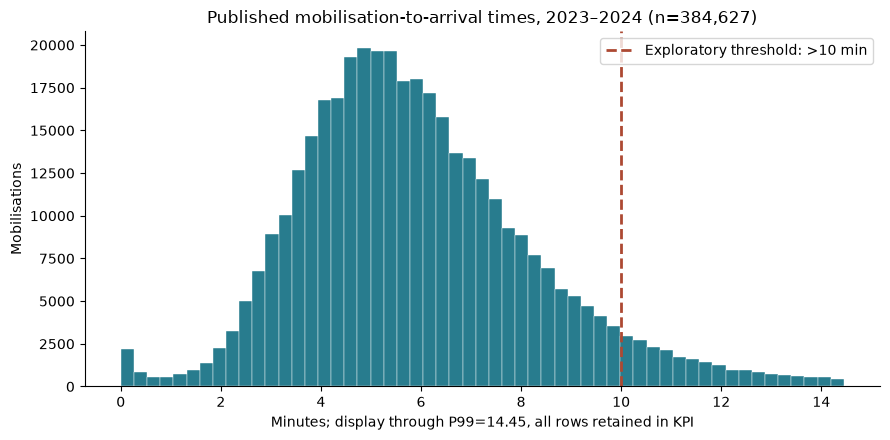

In [5]:
plt.rcParams.update({'font.size':10,'axes.spines.top':False,'axes.spines.right':False})
p99 = case.attendance_min.quantile(.99)
fig, ax = plt.subplots(figsize=(9,4.5))
ax.hist(case.loc[case.attendance_min.le(p99),'attendance_min'],bins=55,color='#287c8e',edgecolor='white',linewidth=.3)
ax.axvline(10,color='#ad4932',linestyle='--',linewidth=2,label='Exploratory threshold: >10 min')
ax.set(title=f'Published mobilisation-to-arrival times, 2023–2024 (n={len(case):,})',
       xlabel=f'Minutes; display through P99={p99:.2f}, all rows retained in KPI',ylabel='Mobilisations')
ax.legend(); fig.tight_layout(); plt.show()

### Figure 2 — Borough comparison
Compare the rate and eligible count for named boroughs. `Unknown` is visible in the table but is not a borough and is not ranked. The comparison is unadjusted for distance, incident mix and resource availability.

,borough,eligible_n,over_10m_n,over_10m_pct,median_min,p90_min
16,HILLINGDON,12195,1563,12.82,6.63,10.67
21,LAMBETH,17210,529,3.07,4.90,7.87
30,Unknown,1288,579,44.95,9.50,15.06


Known-borough-only sensitivity: 25,593/383,339 = 6.676% (all eligible: 6.805%).


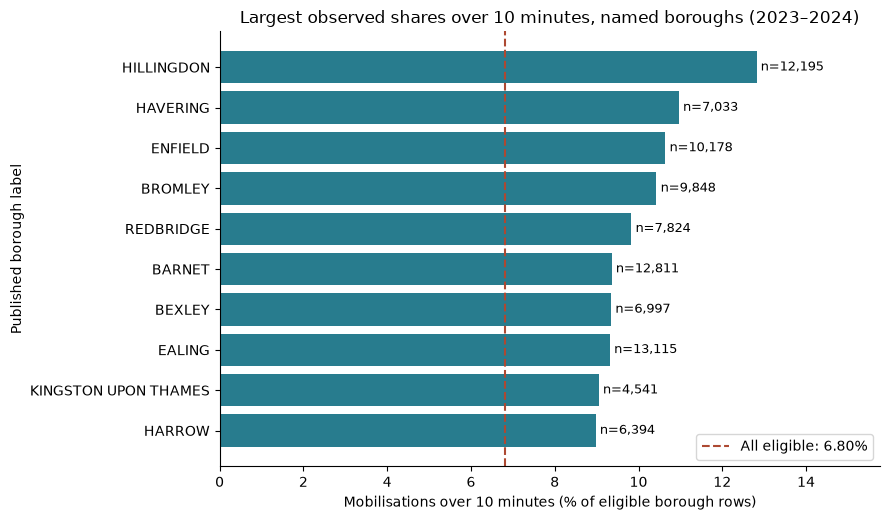

In [6]:
borough = case.groupby('borough',dropna=False).agg(eligible_n=('late_over_10m','size'),
            over_10m_n=('late_over_10m','sum'),over_10m_pct=('late_over_10m',lambda x:100*x.mean()),
            median_min=('attendance_min','median'),p90_min=('attendance_min',lambda x:x.quantile(.9))).reset_index()
borough.to_csv(out/'borough_kpi.csv',index=False)
display(borough[borough.borough.isin(['HILLINGDON','LAMBETH','Unknown'])].round(2))
known = case[case.borough.ne('Unknown')]
print(f'Known-borough-only sensitivity: {known.late_over_10m.sum():,}/{len(known):,} = '
      f'{100*known.late_over_10m.mean():.3f}% (all eligible: {overall.over_10m_pct:.3f}%).')
named = borough[borough.borough.ne('Unknown') & borough.eligible_n.ge(1000)]
top = named.nlargest(10,'over_10m_pct').sort_values('over_10m_pct')
fig,ax=plt.subplots(figsize=(9,5.3))
ax.barh(top.borough,top.over_10m_pct,color='#287c8e')
ax.axvline(overall.over_10m_pct,color='#ad4932',linestyle='--',label=f'All eligible: {overall.over_10m_pct:.2f}%')
ax.set(title='Largest observed shares over 10 minutes, named boroughs (2023–2024)',
       xlabel='Mobilisations over 10 minutes (% of eligible borough rows)',ylabel='Published borough label')
ax.set_xlim(0,top.over_10m_pct.max()*1.23)
for i,row in enumerate(top.itertuples()): ax.text(row.over_10m_pct+.1,i,f'n={row.eligible_n:,}',va='center',fontsize=9)
ax.legend(loc='lower right'); fig.tight_layout(); plt.show()

### Figure 3 — Complete-month trend
The period-wide KPI above includes available December 2024 records. This trend omits that *incomplete month* so adjacent points have complete calendar coverage. A complete calendar month still does not prove all real events were published.

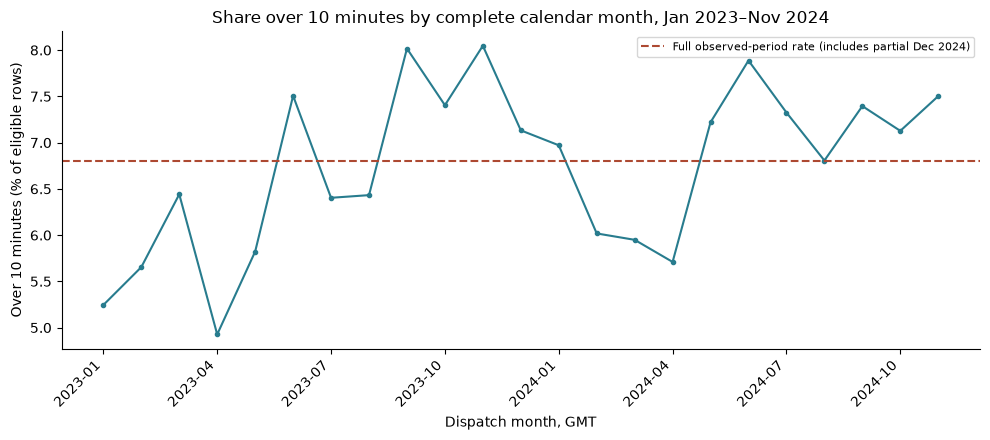

In [7]:
monthly=case.groupby('month').late_over_10m.agg(eligible_n='size',over_10m_n='sum',over_10m_pct=lambda x:100*x.mean()).reset_index()
monthly.to_csv(out/'monthly_kpi.csv',index=False)
complete_months=monthly[monthly.month.ne('2024-12')].copy()
fig,ax=plt.subplots(figsize=(10,4.5))
ax.plot(complete_months.month,complete_months.over_10m_pct,color='#287c8e',marker='o',markersize=3)
ax.axhline(overall.over_10m_pct,color='#ad4932',linestyle='--',label='Full observed-period rate (includes partial Dec 2024)')
ax.set(title='Share over 10 minutes by complete calendar month, Jan 2023–Nov 2024',
       xlabel='Dispatch month, GMT',ylabel='Over 10 minutes (% of eligible rows)')
ax.set_xticks(range(0,len(complete_months),3),complete_months.month.iloc[::3],rotation=45,ha='right')
ax.legend(fontsize=8); fig.tight_layout(); plt.show()

### Figure 4 — Dispatch hour
Each hourly rate pools the available 2023–2024 dispatch dates. Hour labels are GMT, not local daylight-saving time. A higher rate at an hour does not prove traffic or staffing caused it.

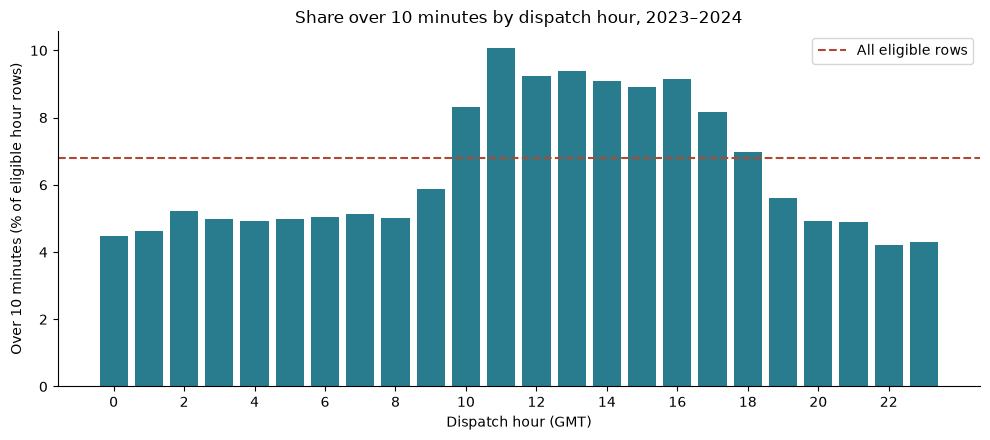

,hour_gmt,eligible_n,over_10m_n,over_10m_pct
11,11,19425,1955,10.06
13,13,19755,1857,9.40
12,12,19976,1845,9.24


In [8]:
hourly=case.groupby('hour_gmt').late_over_10m.agg(eligible_n='size',over_10m_n='sum',over_10m_pct=lambda x:100*x.mean()).reset_index()
hourly.to_csv(out/'hour_kpi.csv',index=False)
fig,ax=plt.subplots(figsize=(10,4.5))
ax.bar(hourly.hour_gmt,hourly.over_10m_pct,color='#287c8e')
ax.axhline(overall.over_10m_pct,color='#ad4932',linestyle='--',label='All eligible rows')
ax.set(title='Share over 10 minutes by dispatch hour, 2023–2024',xlabel='Dispatch hour (GMT)',
       ylabel='Over 10 minutes (% of eligible hour rows)',xticks=range(0,24,2))
ax.legend(); fig.tight_layout(); plt.show()
display(hourly.nlargest(3,'over_10m_pct').round(2))

**Interpretation of the revised EDA.** The new percentage gives the numerator and denominator behind each comparison, while the median and P90 still describe distribution shape. The 1,288 `Unknown`-borough rows have an unusually high over-10-minute share (44.95%); excluding them reduces the overall rate from 6.805% to about 6.676%. This is a material geographic missingness warning, so do not treat named-borough comparisons as complete coverage. Hillingdon is an example for contextual review, not a service-quality ranking. Differences can arise from distance, incident type, deployment location and other unmeasured factors. No causal claim follows from these figures. The historical source also has an absent day and no observed duration above 20 minutes.

## Sampling and representativeness
We draw approximately one quarter of the eligible published rows with a fixed seed **only to demonstrate sampling**. We compare the KPI and the share of Hillingdon and Unknown rows with the complete observed analytical case. Agreement would show that the subsample resembles this file on these measures; it would not establish that the file represents all real LFB mobilisations. Coverage/selection bias and missing geography remain.

In [9]:
rng=np.random.default_rng(SEED)
sample_indices=rng.choice(len(case),size=round(len(case)*.25),replace=False)
sample=case.iloc[np.sort(sample_indices)].copy()
def sample_view(frame):
    return pd.Series({'n':len(frame),'over_10m_pct':100*frame.late_over_10m.mean(),
                      'hillingdon_share_pct':100*frame.borough.eq('HILLINGDON').mean(),
                      'unknown_share_pct':100*frame.borough.eq('Unknown').mean()})
sample_comparison=pd.concat({'Full observed case':sample_view(case),'25% random sample':sample_view(sample)},axis=1).T
sample_comparison['KPI difference vs full (pp)']=sample_comparison.over_10m_pct-sample_comparison.loc['Full observed case','over_10m_pct']
sample_comparison.to_csv(out/'sample_comparison.csv')
display(sample_comparison.round(3))
print('This is population sampling inside the available file, not the train/test split below.')

,n,over_10m_pct,hillingdon_share_pct,unknown_share_pct,KPI difference vs full (pp)
Full observed case,384627.0,6.805,3.171,0.335,0.000
25% random sample,96157.0,6.867,3.226,0.341,0.062


This is population sampling inside the available file, not the train/test split below.


## Leakage audit
The hypothetical prediction would occur **at the instant of mobilisation**. The target is whether the recorded duration later exceeds 600 seconds. The table uses fields and process knowledge from the actual C1 case; `uncertain` is not silently treated as available. Training/validation/test boundaries are verified in the following section.

In [10]:
leakage=pd.DataFrame([
 {'risk':'Outcome and target-derived values','status':'present in source','evidence':'AttendanceTimeSeconds, attendance_min and late_over_10m are calculated after arrival','consequence':'Near-perfect target leakage','mitigation':'Outcome is evaluation target only; never a dispatch-time feature'},
 {'risk':'Future timestamps and duration components','status':'present in source','evidence':'DateAndTimeArrived, TurnoutTimeSeconds, TravelTimeSeconds and delay codes are post-dispatch','consequence':'Future information enters predictors','mitigation':'Exclude from any dispatch-time feature set'},
 {'risk':'Several vehicles for one incident','status':'present','evidence':f'{len(case):,} mobilisations versus {case.IncidentNumber.nunique():,} incident IDs','consequence':'Related incidents can cross partitions and inflate apparent generalisation','mitigation':'Verify IncidentNumber sets are disjoint across chronological partitions'},
 {'risk':'Borough label available at dispatch','status':'uncertain','evidence':'BoroughName is a published label; metadata does not establish decision-time availability','consequence':'Potential after-event location leakage','mitigation':'Exclude from hypothetical dispatch features until operational timing is verified'},
 {'risk':'Full-data inspection and threshold choice','status':'present','evidence':'W1/C1 inspected the whole 2023–2024 file before W2; 10 min was chosen afterward','consequence':'Current test period is not a pristine unseen evaluation','mitigation':'Call holdout retrospective robustness only; use later untouched data for future model assessment'},
 {'risk':'Preprocessing estimated from all periods','status':'absent in W2 demonstration','evidence':'Hour scaler below is fitted on train only','consequence':'Global fit would transfer future distribution into training','mitigation':'Fit on train; apply unchanged to validation/test'}
])
leakage.to_csv(out/'leakage_audit.csv',index=False)
display(leakage)

,risk,status,evidence,consequence,mitigation
0,Outcome and target-derived values,present in source,"AttendanceTimeSeconds, attendance_min and late...",Near-perfect target leakage,Outcome is evaluation target only; never a dis...
1,Future timestamps and duration components,present in source,"DateAndTimeArrived, TurnoutTimeSeconds, Travel...",Future information enters predictors,Exclude from any dispatch-time feature set
2,Several vehicles for one incident,present,"384,627 mobilisations versus 248,225 incident IDs",Related incidents can cross partitions and inf...,Verify IncidentNumber sets are disjoint across...
3,Borough label available at dispatch,uncertain,BoroughName is a published label; metadata doe...,Potential after-event location leakage,Exclude from hypothetical dispatch features un...
4,Full-data inspection and threshold choice,present,W1/C1 inspected the whole 2023–2024 file befor...,Current test period is not a pristine unseen e...,Call holdout retrospective robustness only; us...
5,Preprocessing estimated from all periods,absent in W2 demonstration,Hour scaler below is fitted on train only,Global fit would transfer future distribution ...,Fit on train; apply unchanged to validation/test


## Chronological holdout and internal validation
**Predeclared split:** train = 2023, validation = January–June 2024, test = July–December 2024. These fixed calendar boundaries preserve time order and make the validation period part of the pre-test development window. A random 80/20 row split would mix related vehicles and future records. The test period includes partial December 2024; flag it in interpretation and show a complete-month sensitivity. The main case KPI remains defined on all available 2023–2024 rows. No model is fitted, tuned or scored in W2.

In [11]:
train_end=pd.Timestamp('2024-01-01',tz='UTC')
validation_end=pd.Timestamp('2024-07-01',tz='UTC')
case['split']=np.select([case.DateAndTimeMobilised.lt(train_end),case.DateAndTimeMobilised.lt(validation_end)],
                        ['train','validation'],default='test')
train_df=case[case.split.eq('train')].copy()
validation_df=case[case.split.eq('validation')].copy()
test_df=case[case.split.eq('test')].copy()
partition={'train':train_df,'validation':validation_df,'test':test_df}
split_summary=pd.DataFrame([{'split':name,'n':len(part),'share_pct':100*len(part)/len(case),
                             'date_min':str(part.DateAndTimeMobilised.min()),'date_max':str(part.DateAndTimeMobilised.max())}
                            for name,part in partition.items()])
split_summary.to_csv(out/'split_summary.csv',index=False)
display(split_summary)
incident_sets={name:set(part.IncidentNumber) for name,part in partition.items()}
overlap={f'{a}-{b}':len(incident_sets[a]&incident_sets[b]) for a,b in [('train','validation'),('train','test'),('validation','test')]}
assert all(count==0 for count in overlap.values()),f'Incident overlap requires explicit boundary handling: {overlap}'
assert sum(len(part) for part in partition.values())==len(case)
assert train_df.DateAndTimeMobilised.max()<validation_df.DateAndTimeMobilised.min()<test_df.DateAndTimeMobilised.min()
assignment=case[['ResourceMobilisationId','IncidentNumber','DateAndTimeMobilised','split']]
assignment.to_csv(out/'split_assignment.csv.gz',index=False,compression='gzip')
print('Incident overlap:',overlap,'| missing split rows:',case.split.isna().sum())

,split,n,share_pct,date_min,date_max
0,train,186339,48.446677,2023-01-01 00:00:27+00:00,2023-12-31 23:59:24+00:00
1,validation,96040,24.969646,2024-01-01 00:00:43+00:00,2024-06-30 23:58:07+00:00
2,test,102248,26.583677,2024-07-01 00:07:12+00:00,2024-12-30 23:59:59+00:00


Incident overlap: {'train-validation': 0, 'train-test': 0, 'validation-test': 0} | missing split rows: 0


### Train-only fitted operation
For a transparent preprocessing demonstration, estimate the mean and standard deviation of **dispatch hour** using train rows only, then apply those frozen parameters to validation and test. Hour is known at mobilisation, unlike arrival or travel time. Linear scaling is an instructional transformation, not a claim that hour is linear rather than circular. No target values are used to fit it, and no model is trained.

In [12]:
hour_mean=train_df.hour_gmt.mean()
hour_std=train_df.hour_gmt.std(ddof=0)
assert hour_std>0
hour_scaled={name:(part.hour_gmt-hour_mean)/hour_std for name,part in partition.items()}
assert abs(hour_scaled['train'].mean())<1e-10
print(f'Train-fitted hour mean={hour_mean:.4f}, std={hour_std:.4f}; frozen on validation and test.')
display(pd.DataFrame([{'split':name,'scaled_hour_mean':values.mean(),'scaled_hour_std':values.std(ddof=0)}
                      for name,values in hour_scaled.items()]).round(3))

Train-fitted hour mean=13.2656, std=6.2807; frozen on validation and test.


,split,scaled_hour_mean,scaled_hour_std
0,train,-0.000,1.000
1,validation,0.000,1.003
2,test,-0.012,1.000


### Final retrospective robustness read
Only now inspect the outcome rates across the predeclared periods. This is **not predictive accuracy**. The full-data EDA from W1/C1, the fixed threshold choice and partial December 2024 limit claims of an untouched test. Future C2 modeling would require a genuinely later, uninspected holdout and an incident-group-safe validation plan.

In [13]:
holdout=pd.DataFrame([{'split':name,'eligible_n':len(part),'over_10m_n':int(part.late_over_10m.sum()),
                      'over_10m_pct':100*part.late_over_10m.mean(),
                      'hillingdon_share_pct':100*part.borough.eq('HILLINGDON').mean()}
                     for name,part in partition.items()])
holdout.to_csv(out/'holdout_kpi.csv',index=False)
display(holdout.round(3))
test_complete_months=test_df[test_df.DateAndTimeMobilised.lt(pd.Timestamp('2024-12-01',tz='UTC'))]
print(f'Test July–November 2024 (complete calendar months): n={len(test_complete_months):,}, '
      f'over-10-min rate={100*test_complete_months.late_over_10m.mean():.3f}%; '
      f'test including partial December: {100*test_df.late_over_10m.mean():.3f}%')

,split,eligible_n,over_10m_n,over_10m_pct,hillingdon_share_pct
0,train,186339,12399,6.654,3.122
1,validation,96040,6392,6.656,3.142
2,test,102248,7381,7.219,3.285


Test July–November 2024 (complete calendar months): n=86,547, over-10-min rate=7.231%; test including partial December: 7.219%


## Takeaways and management summary
**Managerial summary (120–180 words).** We continued the C1 investigation of published London Fire Brigade vehicle mobilisation-to-arrival times, while replacing its primary P90 measure after the instructor's reported feedback. The revised KPI is the percentage of eligible mobilisations lasting more than ten minutes. It is 6.81% across 384,627 observed 2023–2024 records; P90 and the median remain supporting summaries. Borough and dispatch-hour differences identify where an analyst might investigate, but do not establish their causes or justify resource changes. Validation reconfirmed unique mobilisation IDs, nonnegative and timestamp-consistent durations, and the C1 row flow. The 1,288 rows without a borough label have a 44.95% over-ten-minute rate and remain in the total. A fixed-seed quarter-sample resembles the available file on selected comparisons, but cannot repair publication and coverage bias. Chronological train, validation and test subsets have no incident overlap. The test is a retrospective robustness calculation, since C1 already examined the full dataset. Next, verify field availability at dispatch and obtain later, untouched records before predictive evaluation or operational recommendations.

**AI-use disclosure.** OpenAI Codex assisted with the KPI reformulation, notebook code, quality checks and explanatory draft. The team must inspect and defend the calculations, assumptions and interpretations. This file does not claim independent instructor approval or that the ten-minute threshold is an official standard.